In [2]:
from torchvision import datasets
from torch.utils.data import DataLoader, Subset
import torchvision.transforms as transforms
import torch
import torch.nn as nn
from torch.optim import Adam
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import os, copy

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

# Fix random seeds for reproducible results
torch.manual_seed(42)
np.random.seed(42)

cuda


In [3]:
# Automatically locate the folder that directly contains the 8 class folders
def find_class_root(root, n_classes=8):
    for current, subdirs, files in os.walk(root):
        subdirs = [d for d in subdirs if not d.startswith('.') and d != '__MACOSX']
        if len(subdirs) == n_classes:
            return current
    return None

data_folder = find_class_root("/kaggle/input")
print("Dataset folder:", data_folder)
print("Classes:", sorted(os.listdir(data_folder)))

Dataset folder: /kaggle/input/datasets/mstfabihaafifa/mangoleafbd-dataset/MangoLeafBD Dataset
Classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']


Total images: 4000
Number of classes: 8
Anthracnose         : 500
Bacterial Canker    : 500
Cutting Weevil      : 500
Die Back            : 500
Gall Midge          : 500
Healthy             : 500
Powdery Mildew      : 500
Sooty Mould         : 500


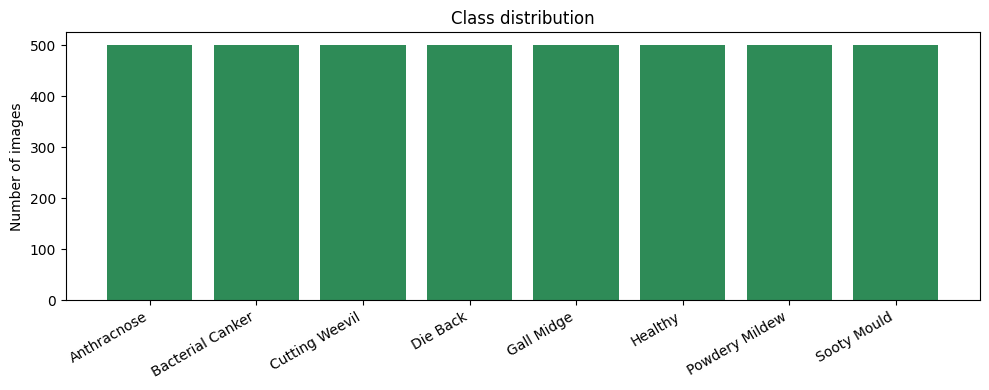

Original image size (W x H): (320, 240)


In [4]:
# ImageFolder assigns labels from folder names (alphabetical order: 0, 1, 2, ...)
full_data = datasets.ImageFolder(data_folder)
class_names = full_data.classes
NUM_CLASSES = len(class_names)

print("Total images:", len(full_data))
print("Number of classes:", NUM_CLASSES)

counts = np.bincount(full_data.targets)
for name, c in zip(class_names, counts):
    print(f"{name:20s}: {c}")

plt.figure(figsize=(10, 4))
plt.bar(class_names, counts, color="seagreen")
plt.xticks(rotation=30, ha="right")
plt.ylabel("Number of images")
plt.title("Class distribution")
plt.tight_layout()
plt.show()

sample_img, _ = full_data[0]
print("Original image size (W x H):", sample_img.size)

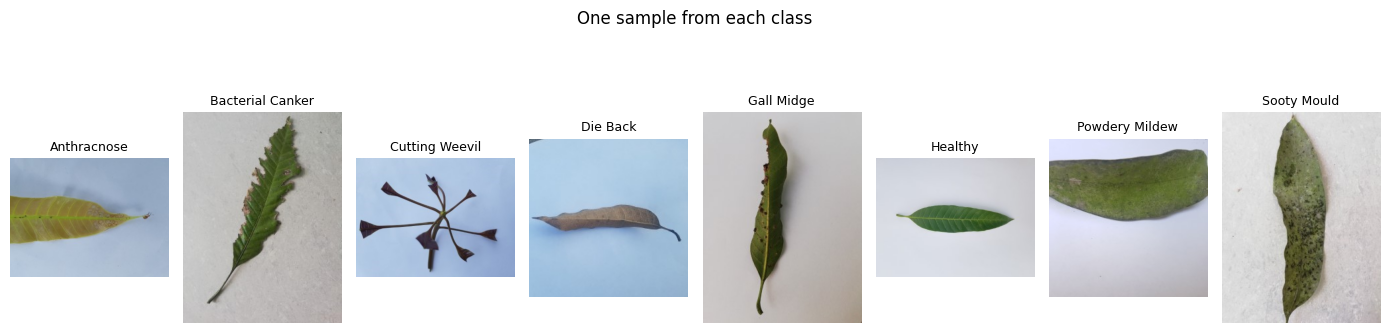

In [5]:
# Show one sample image from each class
plt.figure(figsize=(14, 4))
for i, cls in enumerate(class_names):
    idx = full_data.targets.index(i)          # first image of this class
    img, _ = full_data[idx]
    plt.subplot(1, NUM_CLASSES, i + 1)
    plt.imshow(img)
    plt.title(cls, fontsize=9)
    plt.axis("off")
plt.suptitle("One sample from each class")
plt.tight_layout()
plt.show()

In [6]:
targets = np.array(full_data.targets)
rng = np.random.RandomState(42)

train_idx, val_idx, test_idx = [], [], []
for c in range(NUM_CLASSES):
    idx = np.where(targets == c)[0]
    rng.shuffle(idx)
    n_train = int(0.70 * len(idx))
    n_val = int(0.15 * len(idx))
    train_idx += idx[:n_train].tolist()
    val_idx   += idx[n_train:n_train + n_val].tolist()
    test_idx  += idx[n_train + n_val:].tolist()

print("Train:", len(train_idx), "| Val:", len(val_idx), "| Test:", len(test_idx))

Train: 2800 | Val: 600 | Test: 600


In [7]:
# Important hyperparameters
IMG_SIZE = 128
batch_size_no = 32
learning_rate = 1e-3

basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

aug_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),                       # left-right flip
    transforms.RandomVerticalFlip(),                         # up-down flip
    transforms.RandomRotation(20),                           # rotate ±20 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2),    # lighting changes
    transforms.ToTensor(),
])
print("Transforms ready")

Transforms ready


In [8]:
def get_data(train_transform):
    # Same image folder, loaded twice: once with the training transform, once clean
    train_set = datasets.ImageFolder(data_folder, transform=train_transform)
    clean_set = datasets.ImageFolder(data_folder, transform=basic_transform)

    trn_dl  = DataLoader(Subset(train_set, train_idx), batch_size=batch_size_no, shuffle=True,  num_workers=2)
    val_dl  = DataLoader(Subset(clean_set, val_idx),   batch_size=batch_size_no, shuffle=False, num_workers=2)
    test_dl = DataLoader(Subset(clean_set, test_idx),  batch_size=batch_size_no, shuffle=False, num_workers=2)
    return trn_dl, val_dl, test_dl

trn_dl, val_dl, test_dl = get_data(basic_transform)

x, y = next(iter(trn_dl))
print("One batch:", x.shape, y.shape)

One batch: torch.Size([32, 3, 128, 128]) torch.Size([32])


In [9]:
def get_model(p_dropout=0.0):
    model = nn.Sequential(
        #Feature Extraction
        #image size 128x128
        nn.Conv2d(3, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),    #64x64
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),    #32x32
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),    #16x16

        #Classifier
        nn.Flatten(),
        nn.Linear(64*16*16, 128),   #64x16x16
        nn.ReLU(),
        nn.Dropout(p_dropout),      #0.0 = off (Round 1)
        nn.Linear(128, NUM_CLASSES)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

model, loss_fn, optimizer = get_model()
print(model)
print(f"\nTotal trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=16384, out_features=128, bias=True)
  (11): ReLU()
  (12): Dropout(p=0.0, inplace=False)
  (13): Linear(in_features=128, out_features=8, bias=True)
)

Total trainable parameters: 2,121,896


In [10]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)


@torch.no_grad()
def validate(data_loader, model, loss_fn):
    model.eval()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        prediction = model(x)
        batch_loss = loss_fn(prediction, y)

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)


def fit(model, loss_fn, optimizer, trn_dl, val_dl, epochs):
    train_losses, train_accuracies = [], []
    val_losses, val_accuracies = [], []
    best_acc, best_weights = 0.0, None

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(trn_dl, model, loss_fn, optimizer)
        val_loss, val_acc = validate(val_dl, model, loss_fn)

        train_losses.append(train_loss); train_accuracies.append(train_acc)
        val_losses.append(val_loss);     val_accuracies.append(val_acc)

        # Keep the weights of the best epoch
        if val_acc > best_acc:
            best_acc = val_acc
            best_weights = copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch+1:2d}/{epochs} | "
              f"Train Loss: {train_loss:.4f} Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} Val Acc: {val_acc:.4f}")

    model.load_state_dict(best_weights)   # restore the best weights
    print(f"\nBest validation accuracy: {best_acc:.4f}")
    return {"train_loss": train_losses, "train_acc": train_accuracies,
            "val_loss": val_losses, "val_acc": val_accuracies}


def plot_history(history, title=""):
    ep = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(ep, history["train_loss"], "o-", label="train")
    ax1.plot(ep, history["val_loss"], "o-", label="validation")
    ax1.set_title("Loss (lower = better)"); ax1.set_xlabel("epoch"); ax1.legend(); ax1.grid(True)
    ax2.plot(ep, history["train_acc"], "o-", label="train")
    ax2.plot(ep, history["val_acc"], "o-", label="validation")
    ax2.set_title("Accuracy (higher = better)"); ax2.set_xlabel("epoch"); ax2.legend(); ax2.grid(True)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

print("Functions ready")

Functions ready


Epoch  1/15 | Train Loss: 1.4775 Train Acc: 0.4196 | Val Loss: 0.8642 Val Acc: 0.7217
Epoch  2/15 | Train Loss: 0.6337 Train Acc: 0.7604 | Val Loss: 0.6859 Val Acc: 0.7733
Epoch  3/15 | Train Loss: 0.4579 Train Acc: 0.8314 | Val Loss: 0.3979 Val Acc: 0.8633
Epoch  4/15 | Train Loss: 0.3029 Train Acc: 0.8914 | Val Loss: 0.4112 Val Acc: 0.8633
Epoch  5/15 | Train Loss: 0.2581 Train Acc: 0.9068 | Val Loss: 0.3111 Val Acc: 0.9000
Epoch  6/15 | Train Loss: 0.2115 Train Acc: 0.9236 | Val Loss: 0.2798 Val Acc: 0.9133
Epoch  7/15 | Train Loss: 0.1631 Train Acc: 0.9414 | Val Loss: 0.2460 Val Acc: 0.9283
Epoch  8/15 | Train Loss: 0.1316 Train Acc: 0.9539 | Val Loss: 0.2199 Val Acc: 0.9317
Epoch  9/15 | Train Loss: 0.1010 Train Acc: 0.9661 | Val Loss: 0.2222 Val Acc: 0.9383
Epoch 10/15 | Train Loss: 0.1282 Train Acc: 0.9546 | Val Loss: 0.2831 Val Acc: 0.9067
Epoch 11/15 | Train Loss: 0.0803 Train Acc: 0.9750 | Val Loss: 0.3140 Val Acc: 0.9200
Epoch 12/15 | Train Loss: 0.0811 Train Acc: 0.9718 | V

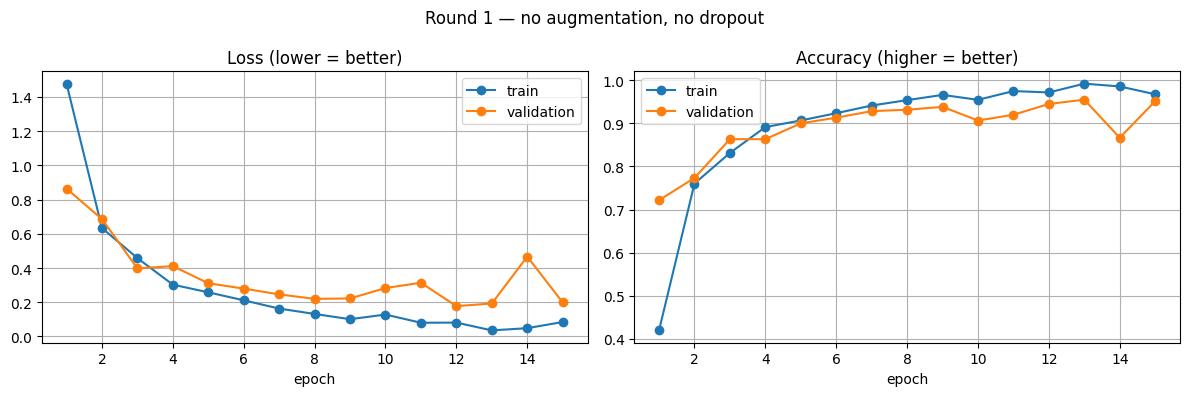

In [11]:
trn_dl, val_dl, test_dl = get_data(basic_transform)
model_plain, loss_fn, optimizer = get_model(p_dropout=0.0)

history_plain = fit(model_plain, loss_fn, optimizer, trn_dl, val_dl, epochs=15)
plot_history(history_plain, "Round 1 — no augmentation, no dropout")

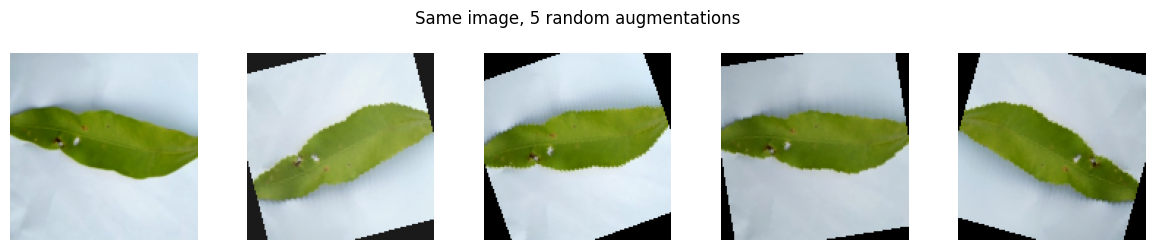

In [12]:
trn_dl_aug, val_dl, test_dl = get_data(aug_transform)

# Fetching the same training image 5 times shows 5 different random augmentations
plt.figure(figsize=(12, 2.5))
for i in range(5):
    aug_img, _ = trn_dl_aug.dataset[0]
    plt.subplot(1, 5, i + 1)
    plt.imshow(aug_img.permute(1, 2, 0))   # [C,H,W] -> [H,W,C] for matplotlib
    plt.axis("off")
plt.suptitle("Same image, 5 random augmentations")
plt.tight_layout()
plt.show()

Epoch  1/30 | Train Loss: 1.8130 Train Acc: 0.2582 | Val Loss: 1.5211 Val Acc: 0.3750
Epoch  2/30 | Train Loss: 1.3381 Train Acc: 0.4439 | Val Loss: 1.0645 Val Acc: 0.6350
Epoch  3/30 | Train Loss: 1.1022 Train Acc: 0.5579 | Val Loss: 0.8714 Val Acc: 0.7117
Epoch  4/30 | Train Loss: 0.9577 Train Acc: 0.6396 | Val Loss: 0.8448 Val Acc: 0.7017
Epoch  5/30 | Train Loss: 0.8966 Train Acc: 0.6646 | Val Loss: 0.6767 Val Acc: 0.7383
Epoch  6/30 | Train Loss: 0.8140 Train Acc: 0.6893 | Val Loss: 0.6914 Val Acc: 0.7550
Epoch  7/30 | Train Loss: 0.7347 Train Acc: 0.7354 | Val Loss: 0.6896 Val Acc: 0.7450
Epoch  8/30 | Train Loss: 0.6984 Train Acc: 0.7418 | Val Loss: 0.4960 Val Acc: 0.8400
Epoch  9/30 | Train Loss: 0.6790 Train Acc: 0.7525 | Val Loss: 0.4756 Val Acc: 0.8500
Epoch 10/30 | Train Loss: 0.6050 Train Acc: 0.7718 | Val Loss: 0.4467 Val Acc: 0.8533
Epoch 11/30 | Train Loss: 0.4935 Train Acc: 0.8118 | Val Loss: 0.6847 Val Acc: 0.7550
Epoch 12/30 | Train Loss: 0.6018 Train Acc: 0.7864 | V

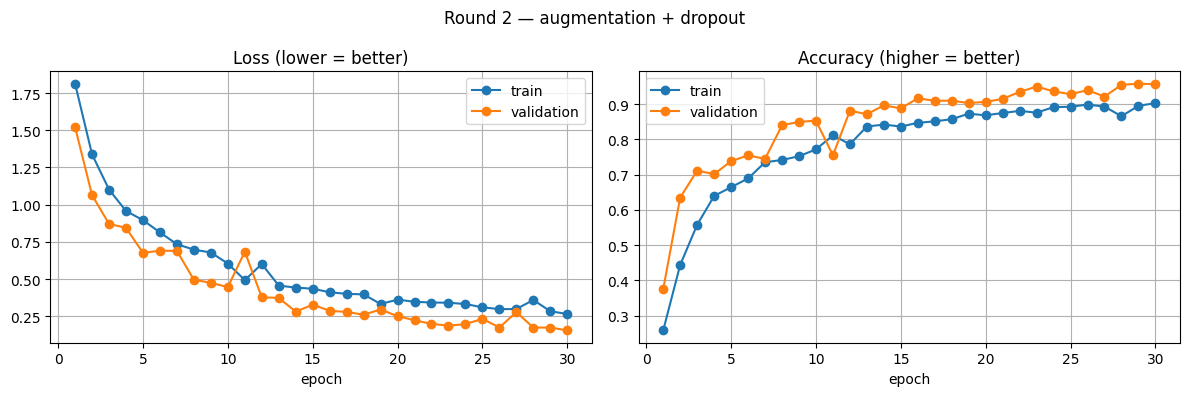

In [13]:
model_aug, loss_fn, optimizer = get_model(p_dropout=0.5)

history_aug = fit(model_aug, loss_fn, optimizer, trn_dl_aug, val_dl, epochs=30)
plot_history(history_aug, "Round 2 — augmentation + dropout")

In [14]:
loss_fn = nn.CrossEntropyLoss()
test_loss_plain, test_acc_plain = validate(test_dl, model_plain, loss_fn)
test_loss_aug,   test_acc_aug   = validate(test_dl, model_aug, loss_fn)
print(f"Round 1 (plain)       -> Test Loss: {test_loss_plain:.4f} | Test Acc: {test_acc_plain*100:.2f}%")
print(f"Round 2 (aug+dropout) -> Test Loss: {test_loss_aug:.4f} | Test Acc: {test_acc_aug*100:.2f}%")

# The better model on the test set becomes the final model
if test_acc_aug >= test_acc_plain:
    final_model, final_name, final_epochs = model_aug, "Round 2 (aug + dropout)", 30
    final_loss, final_acc = test_loss_aug, test_acc_aug
else:
    final_model, final_name, final_epochs = model_plain, "Round 1 (plain)", 15
    final_loss, final_acc = test_loss_plain, test_acc_plain
print("Final model:", final_name)

Round 1 (plain)       -> Test Loss: 0.1683 | Test Acc: 95.00%
Round 2 (aug+dropout) -> Test Loss: 0.1408 | Test Acc: 95.17%
Final model: Round 2 (aug + dropout)


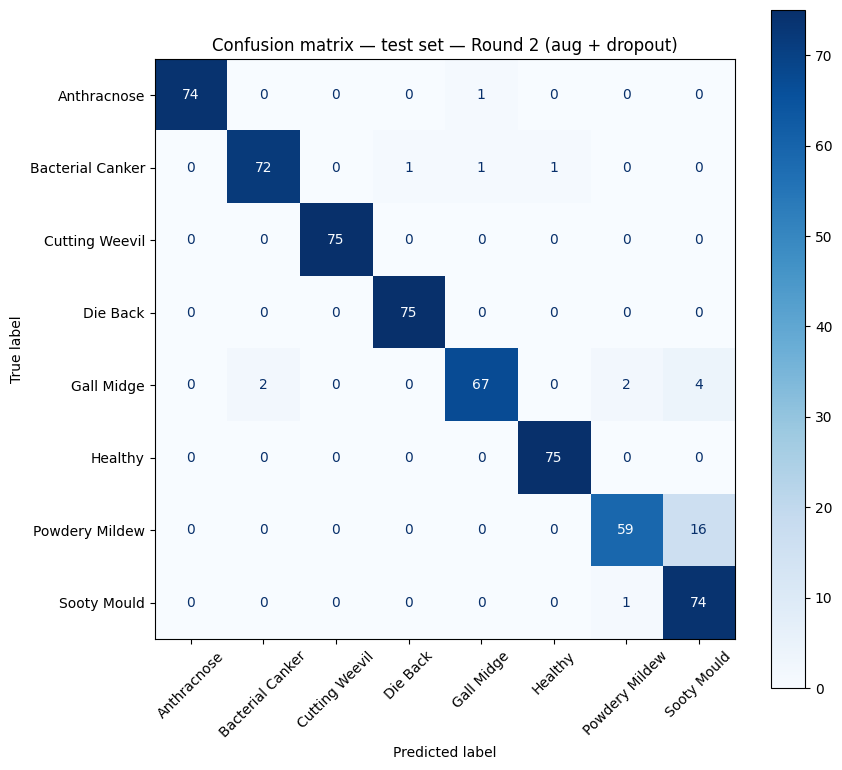

                  precision    recall  f1-score   support

     Anthracnose     1.0000    0.9867    0.9933        75
Bacterial Canker     0.9730    0.9600    0.9664        75
  Cutting Weevil     1.0000    1.0000    1.0000        75
        Die Back     0.9868    1.0000    0.9934        75
      Gall Midge     0.9710    0.8933    0.9306        75
         Healthy     0.9868    1.0000    0.9934        75
  Powdery Mildew     0.9516    0.7867    0.8613        75
     Sooty Mould     0.7872    0.9867    0.8757        75

        accuracy                         0.9517       600
       macro avg     0.9571    0.9517    0.9518       600
    weighted avg     0.9571    0.9517    0.9518       600



In [15]:
@torch.no_grad()
def get_predictions(model, data_loader):
    model.eval()
    preds, targets = [], []
    for x, y in data_loader:
        prediction = model(x.to(device))
        preds.extend(prediction.argmax(-1).cpu().tolist())
        targets.extend(y.tolist())
    return np.array(preds), np.array(targets)

y_pred, y_true = get_predictions(final_model, test_dl)

# Confusion matrix: rows = true class, columns = predicted class
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", values_format="d", ax=ax, xticks_rotation=45)
plt.title(f"Confusion matrix — test set — {final_name}")
plt.tight_layout()
plt.show()

# Per-class precision, recall, F1
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

True class: Anthracnose


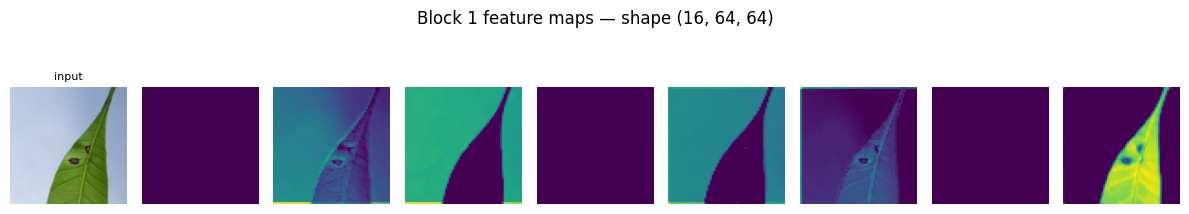

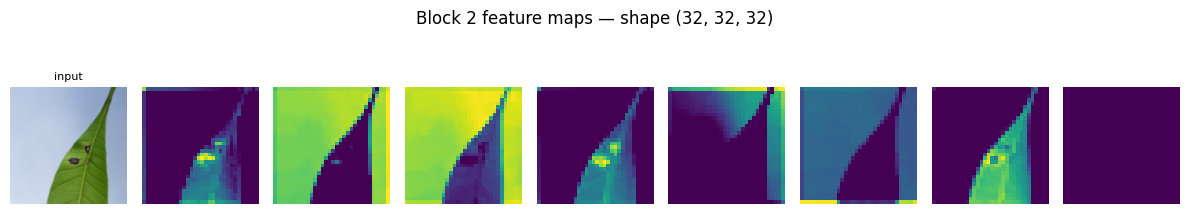

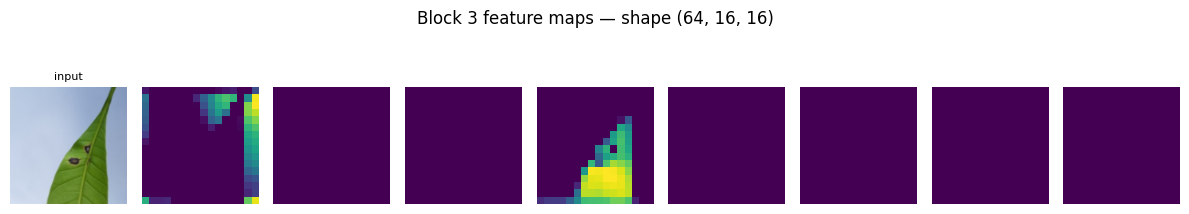

In [16]:
# Feature maps: what each convolution block extracts from one test image
img, label = test_dl.dataset[0]
x = img.unsqueeze(0).to(device)          # add batch dimension: [1, 3, 128, 128]

final_model.eval()
with torch.no_grad():
    block1 = final_model[0:3](x)         # Conv1 + ReLU + MaxPool -> 16 x 64 x 64
    block2 = final_model[0:6](x)         # Conv2 + ReLU + MaxPool -> 32 x 32 x 32
    block3 = final_model[0:9](x)         # Conv3 + ReLU + MaxPool -> 64 x 16 x 16

print("True class:", class_names[label])
for name, fmap in [("Block 1", block1), ("Block 2", block2), ("Block 3", block3)]:
    fmap = fmap.cpu()[0]
    plt.figure(figsize=(12, 2.5))
    plt.subplot(1, 9, 1); plt.imshow(img.permute(1, 2, 0)); plt.title("input", fontsize=8); plt.axis("off")
    for i in range(8):
        plt.subplot(1, 9, i + 2)
        plt.imshow(fmap[i], cmap="viridis")
        plt.axis("off")
    plt.suptitle(f"{name} feature maps — shape {tuple(fmap.shape)}")
    plt.tight_layout()
    plt.show()